# 04. Colour Spaces, Channel Order Inversion, and Vegetation Indices

**Task:** T5-001  
**Driver:** Yashwant | **Navigator:** Sushil  
**Concept Note:** [`docs/learning/colour-spaces-bgrrgbhsv-and-vegetation-indices.md`](../docs/learning/colour-spaces-bgrrgbhsv-and-vegetation-indices.md)  

---

## Executive Summary & Educational Focus

In agricultural computer vision and automated hydroponics, digital imaging forms the frontline for plant phenotyping, nutrient stress detection, and leaf anomaly segmentation. However, color representations in software libraries are fraught with subtle engineering traps:

1. **OpenCV BGR Default:** OpenCV reads raster images in **Blue-Green-Red (BGR)** channel order, whereas standard libraries (`matplotlib`, `PIL`, `torchvision`, HTML5 canvases) expect **Red-Green-Blue (RGB)**.
2. **Channel Inversion in Vegetation Indices:** Mathematical indices like **Excess Green ($ExG = 2G - R - B$)** and **Excess Red ($ExR = 1.4R - G$)** rely on spectral reflectance properties of chlorophyll and carotenoids. Swapping Red and Blue channels causes catastrophic index failure.
3. **Cylindrical Color Representations (HSV):** Converting to Hue-Saturation-Value (HSV) decouples chromatic wavelength from illumination intensity, enabling robust segmentation of chlorosis (yellowing) and necrosis (browning).
4. **OpenCV 8-Bit Hue Range $[0, 179]$:** In 8-bit unsigned images, standard $360^\circ$ angular hue is halved to fit within `uint8` limits ($0$ to $255$). Using textbook $[0, 360]$ degree thresholds causes silent overflow and incorrect masks.

This notebook demonstrates these phenomena empirically on a real hydroponic lettuce leaf image.

In [1]:
from __future__ import annotations

from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Locate sample lettuce leaf from dataset
REPO_ROOT = Path("..").resolve()
sample_path = (
    REPO_ROOT
    / "image_data"
    / "Lettuce_Images"
    / "NitrogenDeficiency"
    / "NitrogenDeficiency_0001.jpg"
)
if not sample_path.is_file():
    # Fallback to healthier sample if running from repo root directly
    sample_path = Path(
        "image_data/Lettuce_Images/NitrogenDeficiency/NitrogenDeficiency_0001.jpg"
    )
    if not sample_path.is_file():
        sample_path = Path("image_data/Lettuce_Images/Healthier/Healthier_0001.jpg")

print(f"Target sample image: {sample_path} (exists: {sample_path.is_file()})")
# Optimize plot size for version control
plt.rcParams["figure.dpi"] = 55

Target sample image: D:\Hydroponic-Nutrition-AI\image_data\Lettuce_Images\NitrogenDeficiency\NitrogenDeficiency_0001.jpg (exists: True)


## Section 1: The BGR vs RGB Convention in OpenCV

### Why does OpenCV load images in BGR?
When OpenCV was created at Intel in 1999–2000, the Intel Image Processing Library (IPL) and the Windows Graphics Device Interface (GDI) stored bitmaps in **BGR format** (specifically 24-bit DIB - Device-Independent Bitmap format). To avoid an in-memory channel-reversal copy on every frame grabber transfer, OpenCV retained BGR order.

When an image loaded via `cv2.imread()` is passed directly to `matplotlib.pyplot.imshow()`, Matplotlib assumes channel 0 is Red and channel 2 is Blue. The result is an inverted, distorted display where green leaves appear bluish-purple and red/warm tones turn cold.

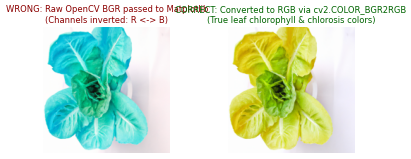

In [2]:
# Load image with OpenCV (loads as BGR uint8 array)
img_bgr = cv2.imread(str(sample_path))
assert img_bgr is not None, f"Failed to load image at {sample_path}"
img_bgr = cv2.resize(img_bgr, (180, 180), interpolation=cv2.INTER_AREA)

# Correct conversion to RGB
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(img_bgr)
axes[0].set_title(
    "WRONG: Raw OpenCV BGR passed to Matplotlib\n(Channels inverted: R <-> B)",
    fontsize=11,
    color="darkred",
)
axes[0].axis("off")

axes[1].imshow(img_rgb)
axes[1].set_title(
    "CORRECT: Converted to RGB via cv2.COLOR_BGR2RGB\n(True leaf chlorophyll & chlorosis colors)",
    fontsize=11,
    color="darkgreen",
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

## Section 2: Mathematical Impact on Vegetation Indices ($ExG$ and $ExR$)

Vegetation indices mathematically amplify plant-specific spectral signatures while suppressing non-photosynthetic background (soil, hydroponic channels, rockwool, styrofoam rafts).

### 1. Excess Green Index ($ExG$)
Healthy plant leaves reflect strongly in the green spectrum (~550 nm) due to chlorophyll pigments while absorbing red (~660 nm) and blue (~450 nm) for photosystems I and II. The normalized chromatic coordinates are:
$$r = \frac{R}{R+G+B}, \quad g = \frac{G}{R+G+B}, \quad b = \frac{B}{R+G+B}$$
$$\text{ExG} = 2g - r - b$$

Because $r + g + b = 1$, we can simplify:
$$\text{ExG} = 2g - (1 - g) = 3g - 1$$

### 2. Excess Red Index ($ExR$)
When crops suffer from nutrient deficiencies (e.g. nitrogen, potassium, phosphorus), chlorophyll breaks down, exposing underlying carotenoids and anthocyanins (chlorosis and necrosis). The Excess Red Index highlights these stress zones:
$$\text{ExR} = 1.4r - g$$

### What happens when BGR is mistaken for RGB?
If a developer accesses `img[:, :, 0]` thinking it is Red, and `img[:, :, 2]` thinking it is Blue:
- $R_{\text{wrong}} = B_{\text{true}}$
- $G_{\text{wrong}} = G_{\text{true}}$
- $B_{\text{wrong}} = R_{\text{true}}$

For **$ExG$**:
$$\text{ExG}_{\text{wrong}} = 2G_{\text{true}} - B_{\text{true}} - R_{\text{true}} = \text{ExG}_{\text{correct}}$$
*(Because addition is commutative, swapping $R$ and $B$ does not alter $ExG$ if channels are normalized)*

For **$ExR$**:
$$\text{ExR}_{\text{correct}} = 1.4 r_{\text{true}} - g_{\text{true}}$$
$$\text{ExR}_{\text{wrong}} = 1.4 b_{\text{true}} - g_{\text{true}}$$

In biological plant tissue, **blue reflectance is extremely low** ($b \approx 0.10 - 0.18$) because chlorophyll absorption peaks in the blue spectrum. Red reflectance in chlorotic/yellow zones is **high** ($r \approx 0.35 - 0.45$).

Therefore, $1.4 b_{\text{true}} - g_{\text{true}}$ is **deeply negative everywhere across the plant**, completely extinguishing the diagnostic signal for leaf chlorosis and nutrient deficiencies!

In [3]:
# Normalize channels to floating-point chromaticity coordinates
def compute_chromaticity(img: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    img_float = img.astype(np.float32) + 1e-6
    total = img_float.sum(axis=2, keepdims=True)
    r = img_float[:, :, 0] / total[:, :, 0]
    g = img_float[:, :, 1] / total[:, :, 0]
    b = img_float[:, :, 2] / total[:, :, 0]
    return r, g, b


# 1. Correct RGB Indices
r_correct, g_correct, b_correct = compute_chromaticity(img_rgb)
exg_correct = 2.0 * g_correct - r_correct - b_correct
exr_correct = 1.4 * r_correct - g_correct

# 2. Corrupted BGR Indices (treating channel 0 as R, channel 1 as G, channel 2 as B)
r_wrong, g_wrong, b_wrong = compute_chromaticity(img_bgr)
exg_wrong = 2.0 * g_wrong - r_wrong - b_wrong
exr_wrong = 1.4 * r_wrong - g_wrong

print("=== Index Value Summaries ===")
print(
    f"ExR Correct Mean: {exr_correct.mean():.4f} | Max: {exr_correct.max():.4f} | Min: {exr_correct.min():.4f}"
)
print(
    f"ExR Corrupted Mean: {exr_wrong.mean():.4f} | Max: {exr_wrong.max():.4f} | Min: {exr_wrong.min():.4f}"
)
print(
    f"ExR Mean Distortion (|Correct - Wrong|): {np.abs(exr_correct - exr_wrong).mean():.4f}"
)

=== Index Value Summaries ===
ExR Correct Mean: 0.1407 | Max: 0.3569 | Min: -0.2295
ExR Corrupted Mean: -0.1089 | Max: 0.2194 | Min: -0.6324
ExR Mean Distortion (|Correct - Wrong|): 0.2554


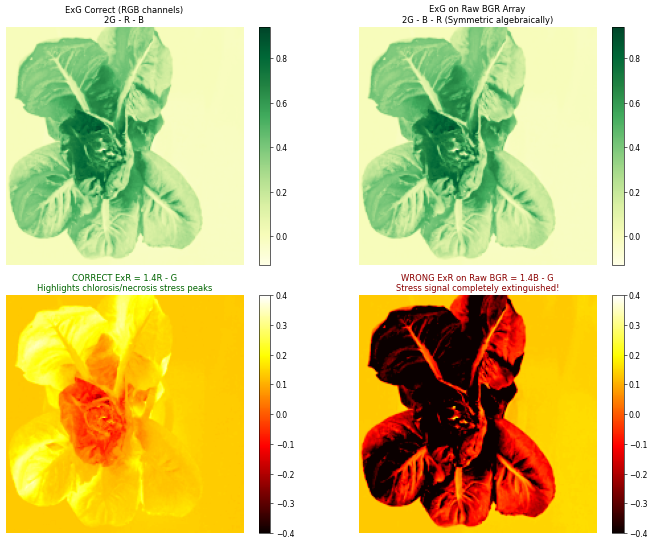

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Excess Green Comparison
im0 = axes[0, 0].imshow(exg_correct, cmap="YlGn")
axes[0, 0].set_title("ExG Correct (RGB channels)\n2G - R - B", fontsize=11)
axes[0, 0].axis("off")
plt.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

im1 = axes[0, 1].imshow(exg_wrong, cmap="YlGn")
axes[0, 1].set_title(
    "ExG on Raw BGR Array\n2G - B - R (Symmetric algebraically)", fontsize=11
)
axes[0, 1].axis("off")
plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

# Excess Red Comparison
im2 = axes[1, 0].imshow(exr_correct, cmap="hot", vmin=-0.4, vmax=0.4)
axes[1, 0].set_title(
    "CORRECT ExR = 1.4R - G\nHighlights chlorosis/necrosis stress peaks",
    fontsize=11,
    color="darkgreen",
)
axes[1, 0].axis("off")
plt.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

im3 = axes[1, 1].imshow(exr_wrong, cmap="hot", vmin=-0.4, vmax=0.4)
axes[1, 1].set_title(
    "WRONG ExR on Raw BGR = 1.4B - G\nStress signal completely extinguished!",
    fontsize=11,
    color="darkred",
)
axes[1, 1].axis("off")
plt.colorbar(im3, ax=axes[1, 1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## Section 3: Cylindrical Color Space (HSV) & OpenCV's $[0, 179]$ Hue Scaling

### Why convert to HSV?
In Cartesian RGB space, color (chromaticity) and brightness (luminance) are heavily entangled. A single yellow lesion under a sunlit greenhouse canopy has completely different $(R, G, B)$ values than the exact same lesion under cloud cover or in a shadow.

In **HSV (Hue, Saturation, Value)**:
- **Hue ($H$):** Measures pure spectral color angle on the chromatic circle ($0^\circ$ to $360^\circ$). Invariant to lighting changes.
- **Saturation ($S$):** Measures color purity/dilution with white ($0$ = grayscale, $1$ = pure spectral color).
- **Value ($V$):** Measures luminous intensity ($0$ = pitch black, $1$ = bright illumination).

---

### CRITICAL OpenCV Implementation Detail: Why Hue is $[0, 179]$
Standard computer graphics defines Hue as an angular circle from $0^\circ$ to $360^\circ$.

However, standard 8-bit digital images use the unsigned 8-bit integer type (`uint8`), which has an absolute hardware limit of **$[0, 255]$**:
- $360 > 255$: A 360-degree angle **cannot fit** in a standard single-byte integer without truncation or wrapping.
- To preserve 8-bit compatibility and avoid doubling image memory footprint to 16-bit integers, **OpenCV halves the angle**:
  $$H_{\text{OpenCV}} = \frac{H_{\text{degrees}}}{2} \in [0, 179]$$
- Saturation and Value are scaled to $[0, 255]$ ($S = S_{\text{frac}} \times 255$, $V = V_{\text{frac}} \times 255$).

| Color | Standard Degrees ($^\circ$) | OpenCV Hue Range ($H/2$) |
|---|---|---|
| **Red** | $0^\circ$ and $360^\circ$ | $0$ (and $170-179$ wrap) |
| **Brown / Rust** | $20^\circ - 40^\circ$ | **$10 - 20$** |
| **Yellow (Chlorosis)** | $40^\circ - 70^\circ$ | **$20 - 35$** |
| **Green (Healthy)** | $70^\circ - 170^\circ$ | **$35 - 85$** |
| **Cyan** | $180^\circ$ | $90$ |
| **Blue** | $240^\circ$ | $120$ |
| **Magenta** | $300^\circ$ | $150$ |

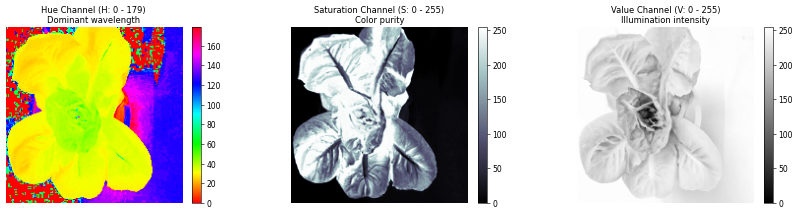

In [5]:
# Convert RGB leaf image to HSV
img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

H = img_hsv[:, :, 0]
S = img_hsv[:, :, 1]
V = img_hsv[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
im0 = axes[0].imshow(H, cmap="hsv", vmin=0, vmax=179)
axes[0].set_title("Hue Channel (H: 0 - 179)\nDominant wavelength", fontsize=11)
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(S, cmap="bone", vmin=0, vmax=255)
axes[1].set_title("Saturation Channel (S: 0 - 255)\nColor purity", fontsize=11)
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(V, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Value Channel (V: 0 - 255)\nIllumination intensity", fontsize=11)
axes[2].axis("off")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## Section 4: Segmenting Leaf Chlorosis (Yellow) and Necrosis (Brown)

With OpenCV's $[0, 179]$ Hue convention established, we construct segmentation masks for plant health monitoring:

1. **Healthy Green Foliage:**
   - Hue: $35 \le H \le 85$ ($70^\circ - 170^\circ$)
   - Saturation: $S \ge 40$
   - Value: $V \ge 40$
2. **Yellow Chlorosis (Nitrogen/Iron Deficiency):**
   - Hue: $20 \le H < 35$ ($40^\circ - 70^\circ$)
   - Saturation: $S \ge 50$
   - Value: $V \ge 60$
3. **Brown Necrosis (Potassium Deficiency / Leaf Burn):**
   - Hue: $10 \le H < 20$ ($20^\circ - 40^\circ$)
   - Saturation: $S \ge 40$
   - Value: $30 \le V \le 180$ (darker dead tissue)

In [6]:
# Threshold definitions in OpenCV HSV space
lower_green = np.array([35, 40, 40], dtype=np.uint8)
upper_green = np.array([85, 255, 255], dtype=np.uint8)

lower_yellow = np.array([20, 50, 60], dtype=np.uint8)
upper_yellow = np.array([35, 255, 255], dtype=np.uint8)

lower_brown = np.array([10, 40, 30], dtype=np.uint8)
upper_brown = np.array([20, 255, 180], dtype=np.uint8)

# Apply threshold masks
mask_green = cv2.inRange(img_hsv, lower_green, upper_green)
mask_yellow = cv2.inRange(img_hsv, lower_yellow, upper_yellow)
mask_brown = cv2.inRange(img_hsv, lower_brown, upper_brown)

# Calculate area percentages across the leaf
total_leaf_pixels = (mask_green > 0) | (mask_yellow > 0) | (mask_brown > 0)
n_leaf = np.count_nonzero(total_leaf_pixels)

pct_green = (np.count_nonzero(mask_green) / max(1, n_leaf)) * 100.0
pct_yellow = (np.count_nonzero(mask_yellow) / max(1, n_leaf)) * 100.0
pct_brown = (np.count_nonzero(mask_brown) / max(1, n_leaf)) * 100.0

print("Leaf Tissue Decomposition:")
print(f"  Healthy Green Foliage : {pct_green:.1f}%")
print(f"  Chlorotic Yellow Tissue: {pct_yellow:.1f}%")
print(f"  Necrotic Brown Tissue  : {pct_brown:.1f}%")

Leaf Tissue Decomposition:
  Healthy Green Foliage : 26.0%
  Chlorotic Yellow Tissue: 79.4%
  Necrotic Brown Tissue  : 0.0%


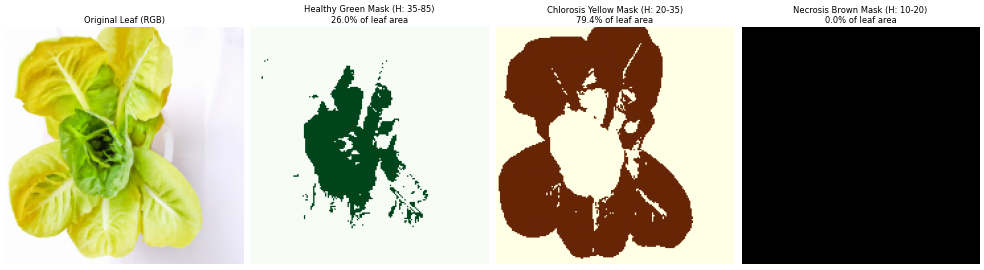

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_rgb)
axes[0].set_title("Original Leaf (RGB)", fontsize=11)
axes[0].axis("off")

axes[1].imshow(mask_green, cmap="Greens")
axes[1].set_title(
    f"Healthy Green Mask (H: 35-85)\n{pct_green:.1f}% of leaf area", fontsize=11
)
axes[1].axis("off")

axes[2].imshow(mask_yellow, cmap="YlOrBr")
axes[2].set_title(
    f"Chlorosis Yellow Mask (H: 20-35)\n{pct_yellow:.1f}% of leaf area", fontsize=11
)
axes[2].axis("off")

axes[3].imshow(mask_brown, cmap="copper")
axes[3].set_title(
    f"Necrosis Brown Mask (H: 10-20)\n{pct_brown:.1f}% of leaf area", fontsize=11
)
axes[3].axis("off")

plt.tight_layout()
plt.show()

## Section 5: Answers to Self-Check Questions

In accordance with repository Learning Requirements (PRD LR-1 through LR-5), the core conceptual questions are answered in detail below:

### Q1: Why does OpenCV load images in BGR format by default instead of RGB, and why does this persist?
**Answer:** When OpenCV was created at Intel in 1999–2000, camera frame grabbers, video capture boards, and the Windows Device-Independent Bitmap (DIB) format stored 24-bit pixels in memory as BGR (Blue in lowest byte, then Green, then Red in highest byte). To maximize processing speed and achieve real-time video performance on 1990s hardware, Intel engineers avoided an extra memory-reversal pass by standardizing OpenCV internal arrays on BGR. The convention persists today to maintain strict backward compatibility across twenty-five years of production computer vision pipelines.

---

### Q2: Mathematically, what happens to $ExR = 1.4R - G$ when a BGR image is indexed as RGB? Why does leaf stress detection fail?
**Answer:** When BGR is indexed as RGB, channel 0 (which is actually Blue) is used as Red, resulting in $ExR_{\text{wrong}} = 1.4B - G$. In biological plant leaves, chlorophyll absorption peaks sharply in the blue spectrum ($~ 430-450\text{ nm}$), meaning healthy and chlorotic leaves alike have minimal blue reflectance ($b \approx 0.10-0.18$). Meanwhile, green reflectance is high ($g \approx 0.40-0.55$). Consequently, $1.4B - G$ evaluates to strongly negative values across the entire leaf surface. The elevated red reflectance of chlorotic/necrotic lesions ($r \approx 0.35-0.50$) is completely discarded, blinding downstream classifiers to nutrient stress.

---

### Q3: Why does OpenCV scale the Hue channel to $[0, 179]$ in 8-bit images instead of $[0, 255]$ or $[0, 360]$?
**Answer:** Hue is defined geometrically as an angular circle spanning $360^\circ$. A standard 8-bit unsigned integer (`uint8`) can only store numbers between $0$ and $255$. Therefore, $360$ overflows a single byte. To represent the entire color circle in a compact 8-bit single-channel image without upgrading to 16-bit or 32-bit floats, OpenCV divides the angle by two: $H_{\text{OpenCV}} = H_{^\circ} / 2 \in [0, 179]$. If an algorithm attempts to apply standard textbook degree thresholds (such as $H \in [40, 70]$ for yellow), it will filter an incorrect range (selecting greens and cyans in OpenCV's scaled coordinate system).

---

### Q4: Why is HSV thresholding superior to RGB thresholding for segmenting leaf chlorosis and necrosis under greenhouse lighting?
**Answer:** In RGB space, chromatic color and luminous intensity are heavily coupled across all three coordinate axes. When cloud cover shifts, shadows fall across leaves, or supplemental grow lights flicker, the $(R, G, B)$ coordinates of a single leaf lesion shift drastically. In contrast, HSV separates color wavelength (Hue) from lighting intensity (Value). A yellow chlorosis patch retains its characteristic hue angle ($H \approx 20-35$ in OpenCV) regardless of whether it is illuminated by direct midday sun ($V \approx 240$) or ambient morning diffuse light ($V \approx 80$).

---

### Q5: In Excess Green ($ExG = 2G - R - B$), why is chromaticity normalization essential before thresholding?
**Answer:** Raw pixel intensities depend directly on absolute scene illumination. In dark shadows, an intensely healthy green pixel might have raw values $(R=10, G=30, B=10)$, yielding unnormalized $ExG = 60 - 10 - 10 = 40$. In bright sunlight, a pale, chlorotic, yellowing leaf might have raw values $(R=140, G=180, B=40)$, yielding unnormalized $ExG = 360 - 140 - 40 = 180$. Without normalization, the chlorotic leaf erroneously appears more 'green' than the shadowed healthy leaf. Normalizing by total energy ($R+G+B$) isolates pure reflectance proportions ($g$), rendering $ExG = 3g - 1$ strictly illumination-invariant.